Volume shape: (197, 233, 189)
Voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))


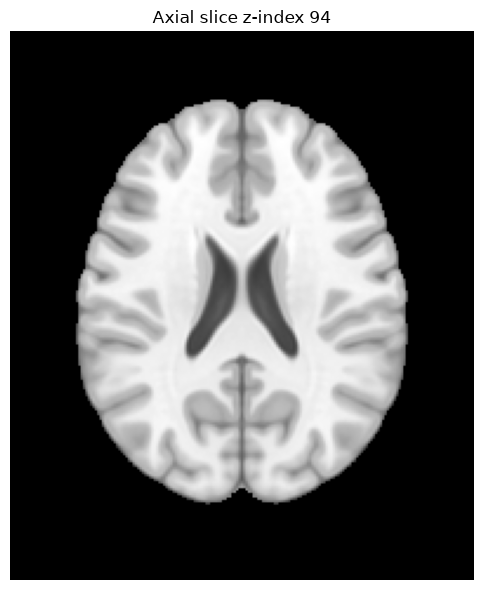

Slice shape: (197, 233) | min/max: 0.0 0.9215686321258545


In [1]:

"""
Load and display an axial MRI slice of the brain from a public dataset.
 
Requirements:
    pip install nilearn nibabel matplotlib numpy
 
Two sources are supported:
  - "mni"   : MNI152 T1 template (ships with nilearn, no download needed)
  - "haxby" : a real subject's T1 anatomical scan from the Haxby 2001 dataset
              (downloaded automatically by nilearn on first use, ~300 MB)
"""
 
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import datasets
 
 
def load_volume(source="mni"):
    """Return a NIfTI image reoriented to RAS (x=left→right, y=back→front, z=bottom→top)."""
    if source == "mni":
        img = datasets.load_mni152_template(resolution=1)
    elif source == "haxby":
        haxby = datasets.fetch_haxby(subjects=[1])
        img = nib.load(haxby.anat[0])
    else:
        raise ValueError("source must be 'mni' or 'haxby'")
 
    # Reorient so the third axis is always inferior→superior (axial slices)
    return nib.as_closest_canonical(img)
 
 
def get_axial_slice(img, z_index=None):
    """Extract a 2D axial slice. Defaults to the middle slice."""
    data = img.get_fdata()
    if z_index is None:
        z_index = data.shape[2] // 2
    return data[:, :, z_index], z_index
 
 
def get_axial_slice_mm(img, z_mm):
    """Extract the axial slice closest to a world coordinate z (in mm)."""
    inv = np.linalg.inv(img.affine)
    _, _, k = nib.affines.apply_affine(inv, [0, 0, z_mm])
    k = int(round(k))
    k = int(np.clip(k, 0, img.shape[2] - 1))
    return get_axial_slice(img, k)
 
 
if __name__ == "__main__":
    img = load_volume("mni")          # change to "haxby" for a real subject scan
    print("Volume shape:", img.shape)
    print("Voxel size (mm):", img.header.get_zooms()[:3])
 
    slice_2d, k = get_axial_slice(img)            # middle slice
    # slice_2d, k = get_axial_slice_mm(img, 10)   # or pick by mm (e.g. z = +10 mm)
 
    # Rotate so anterior is up; shown in neurological convention (left on left)
    plt.figure(figsize=(6, 6))
    plt.imshow(np.rot90(slice_2d), cmap="gray")
    plt.title(f"Axial slice z-index {k}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
 
    # The raw 2D array is ready for further processing:
    print("Slice shape:", slice_2d.shape, "| min/max:", slice_2d.min(), slice_2d.max())
    

Max reconstruction error: 1.9984014443252818e-15


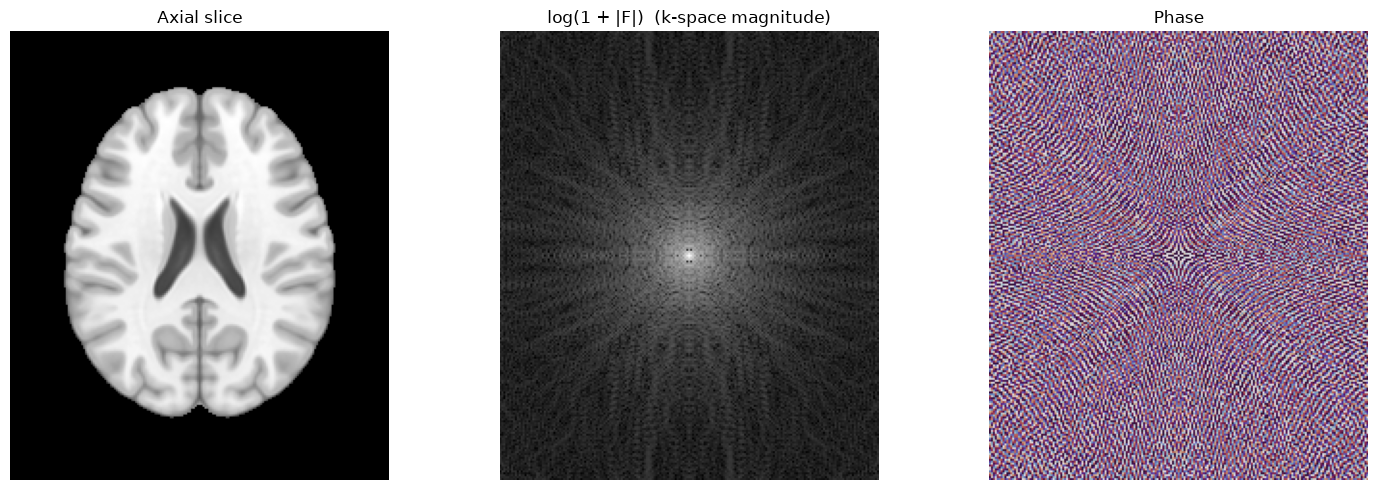

In [2]:
import numpy as np
import matplotlib.pyplot as plt

img2d = np.rot90(slice_2d)                 # same orientation as the display

# 2D FFT, with the zero frequency (DC) moved to the centre
F = np.fft.fftshift(np.fft.fft2(img2d))

magnitude = np.abs(F)
phase = np.angle(F)
log_mag = np.log1p(magnitude)              # log scale, otherwise only the DC spike is visible

# Sanity check: the inverse FFT should give back the original image
recon = np.real(np.fft.ifft2(np.fft.ifftshift(F)))
print("Max reconstruction error:", np.abs(recon - img2d).max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img2d, cmap="gray")
axes[0].set_title("Axial slice")
axes[1].imshow(log_mag, cmap="gray")
axes[1].set_title("log(1 + |F|)  (k-space magnitude)")
axes[2].imshow(phase, cmap="twilight")
axes[2].set_title("Phase")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

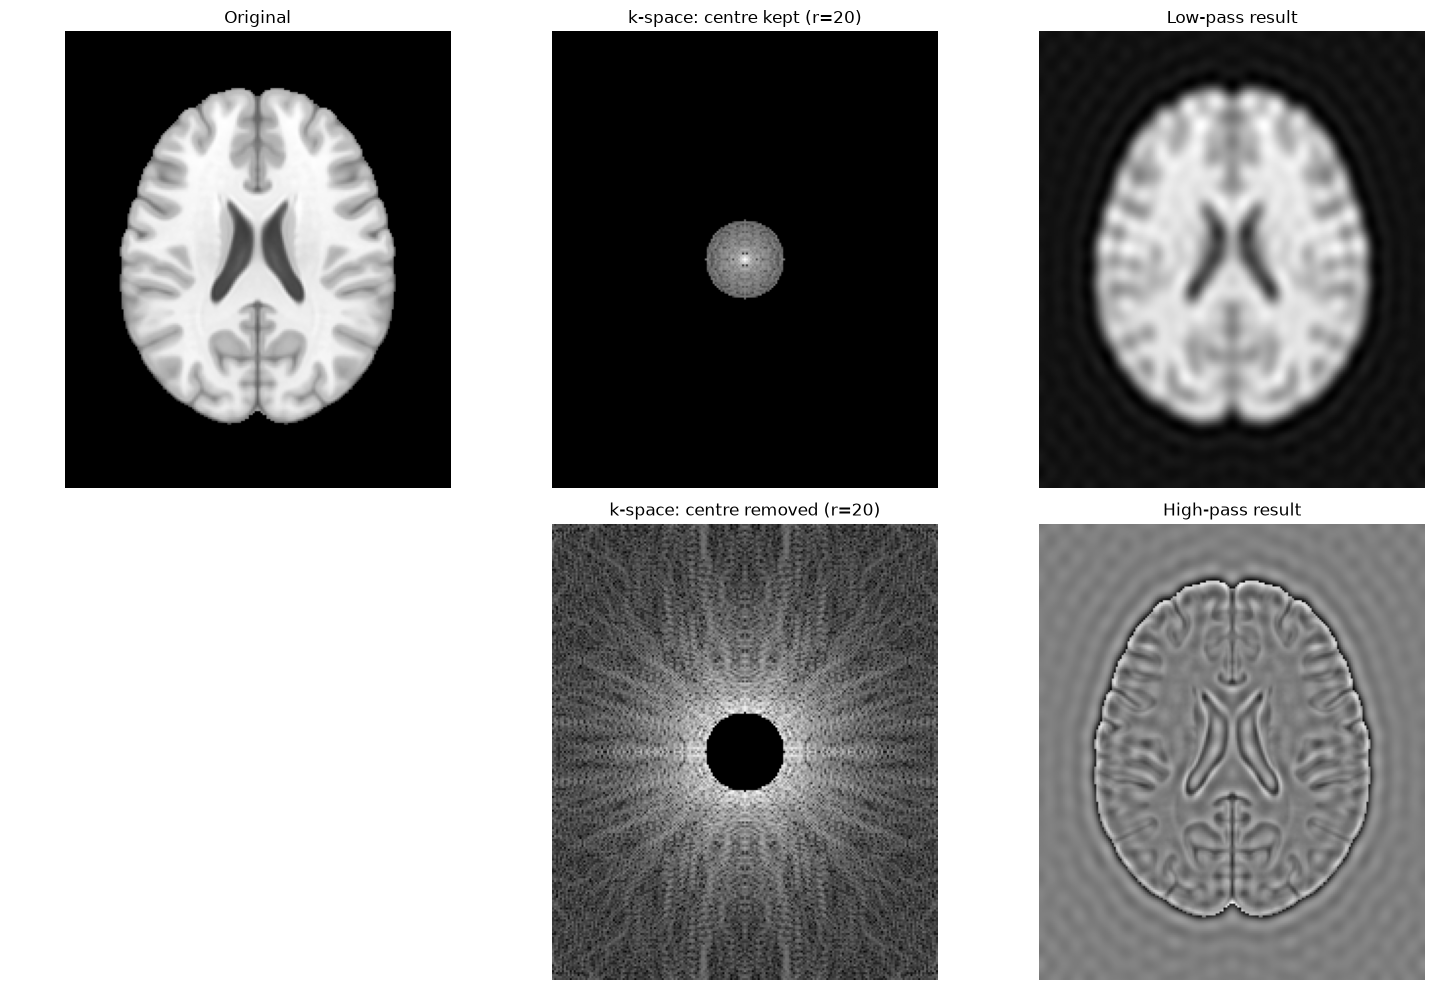

In [3]:
radius = 20                                     # circle radius in pixels of k-space

rows, cols = F.shape
cy, cx = rows // 2, cols // 2                   # centre of the shifted spectrum
y, x = np.ogrid[:rows, :cols]
circle = (y - cy) ** 2 + (x - cx) ** 2 <= radius ** 2

F_low = F * circle                              # keep only the centre
F_high = F * ~circle                            # remove the centre

img_low = np.real(np.fft.ifft2(np.fft.ifftshift(F_low)))
img_high = np.real(np.fft.ifft2(np.fft.ifftshift(F_high)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(img2d, cmap="gray")
axes[0, 0].set_title("Original")
axes[0, 1].imshow(np.log1p(np.abs(F_low)), cmap="gray")
axes[0, 1].set_title(f"k-space: centre kept (r={radius})")
axes[0, 2].imshow(img_low, cmap="gray")
axes[0, 2].set_title("Low-pass result")
axes[1, 0].axis("off")
axes[1, 1].imshow(np.log1p(np.abs(F_high)), cmap="gray")
axes[1, 1].set_title(f"k-space: centre removed (r={radius})")
axes[1, 2].imshow(img_high, cmap="gray")
axes[1, 2].set_title("High-pass result")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

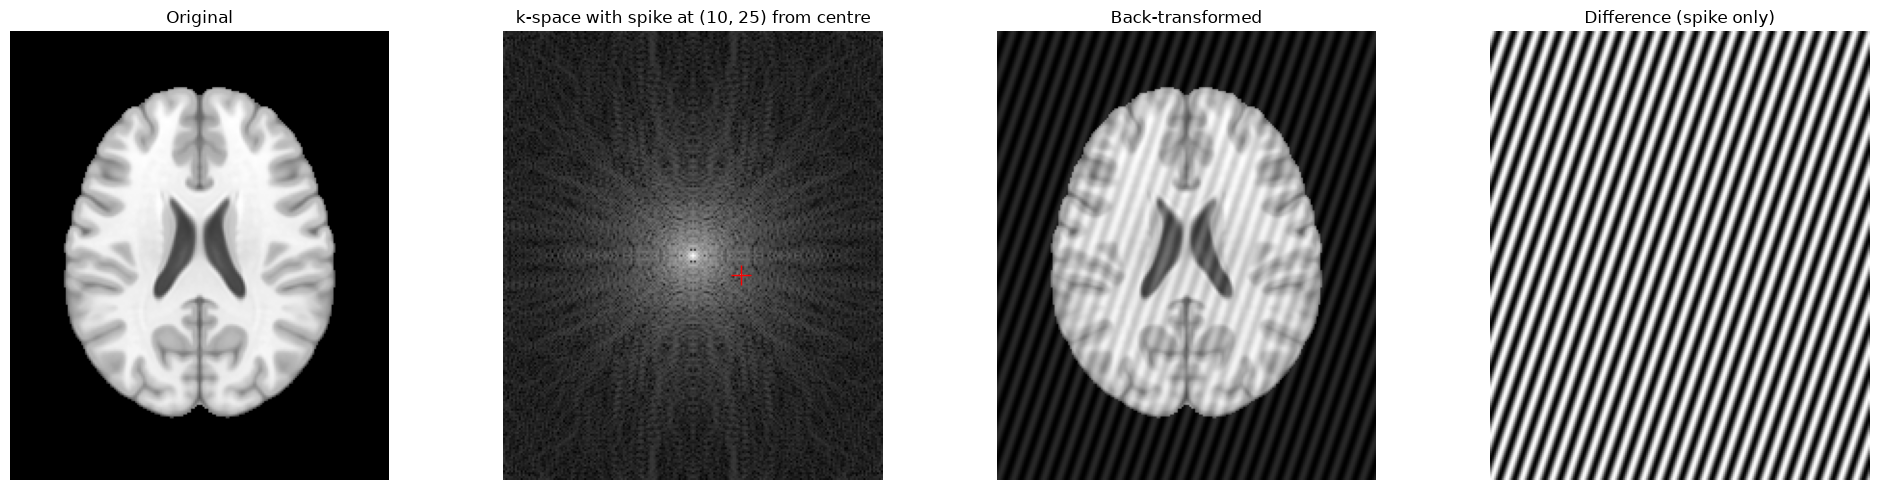

In [ ]:
dy, dx = 10, 25                          # offset of the spike from the centre, in pixels
strength = 0.3                           # spike brightness relative to the DC (centre) value

F_spike = F.copy()
F_spike[cy + dy, cx + dx] += strength * np.abs(F).max()

img_spike = np.real(np.fft.ifft2(np.fft.ifftshift(F_spike)))
stripes = img_spike - img2d              # what the spike added on its own

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img2d, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(np.log1p(np.abs(F_spike)), cmap="gray")
#axes[1].plot(cx + dx, cy + dy, "r+", markersize=15)
axes[1].set_title(f"k-space with spike at ({dy}, {dx}) from centre")
axes[2].imshow(img_spike, cmap="gray")
axes[2].set_title("Back-transformed")
axes[3].imshow(stripes, cmap="gray")
axes[3].set_title("Difference (spike only)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()